# Regression Track — Financial Risk for Loan Approval\n\n**23CSE301 Machine Learning Capstone — Review 1**\n\n**Dataset:** `data/financial_risk_loan_approval/Loan.csv` (20,000 rows x 36 columns, synthetically generated loan-application data).\n\n**Problem statement:** Predict a continuous **`RiskScore`** (a lender's overall risk assessment of an applicant, roughly 28-84) from applicant demographic, financial and credit-history attributes.\n\n**Pipeline covered in this notebook:**\n1. Data loading & audit\n2. Exploratory Data Analysis (EDA)\n3. Data cleaning, feature engineering, encoding, scaling, splitting\n4. Training and comparing **all 10 required regression algorithms**\n5. Hyperparameter tuning (GridSearchCV) on the two best models\n6. 5-fold cross-validated R² for the two best models\n7. Result visualisation (residuals, predicted-vs-actual, feature importance)\n\nRandom seed `42` is used everywhere for reproducibility."


In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams['figure.dpi'] = 100

DATA_PATH = '../data/financial_risk_loan_approval/Loan.csv'

## Section A — Dataset Loading & Audit (A1)

In [2]:
df = pd.read_csv(DATA_PATH)

print(f'Shape: {df.shape[0]} rows x {df.shape[1]} columns')
print()
print('Data types:')
print(df.dtypes)

Shape: 20000 rows x 36 columns

Data types:
ApplicationDate                object
Age                             int64
AnnualIncome                    int64
CreditScore                     int64
EmploymentStatus               object
EducationLevel                 object
Experience                      int64
LoanAmount                      int64
LoanDuration                    int64
MaritalStatus                  object
NumberOfDependents              int64
HomeOwnershipStatus            object
MonthlyDebtPayments             int64
CreditCardUtilizationRate     float64
NumberOfOpenCreditLines         int64
NumberOfCreditInquiries         int64
DebtToIncomeRatio             float64
BankruptcyHistory               int64
LoanPurpose                    object
PreviousLoanDefaults            int64
PaymentHistory                  int64
LengthOfCreditHistory           int64
SavingsAccountBalance           int64
CheckingAccountBalance          int64
TotalAssets                     int64
TotalL

In [3]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print('Columns with missing values:')
print(missing if len(missing) else 'None — the dataset has no missing values.')

print(f'\nDuplicate rows: {df.duplicated().sum()}')

print('\nTarget (RiskScore) distribution:')
print(df['RiskScore'].describe())

Columns with missing values:
None — the dataset has no missing values.

Duplicate rows: 0

Target (RiskScore) distribution:
count    20000.000000
mean        50.766780
std          7.778262
min         28.800000
25%         46.000000
50%         52.000000
75%         56.000000
max         84.000000
Name: RiskScore, dtype: float64


**Observation:** The dataset has 20,000 rows and 36 columns (30 numeric, 6 categorical/text) with **no missing values and no duplicate rows**, so no imputation is strictly required. `RiskScore` (the regression target) is roughly bell-shaped, centred around 51 with a range of ~29-84, so it behaves like a well-conditioned continuous target for regression.

## Section A — EDA Visualisations (A2)

### A2.1 Distribution of every feature

30 numeric columns, 5 categorical columns


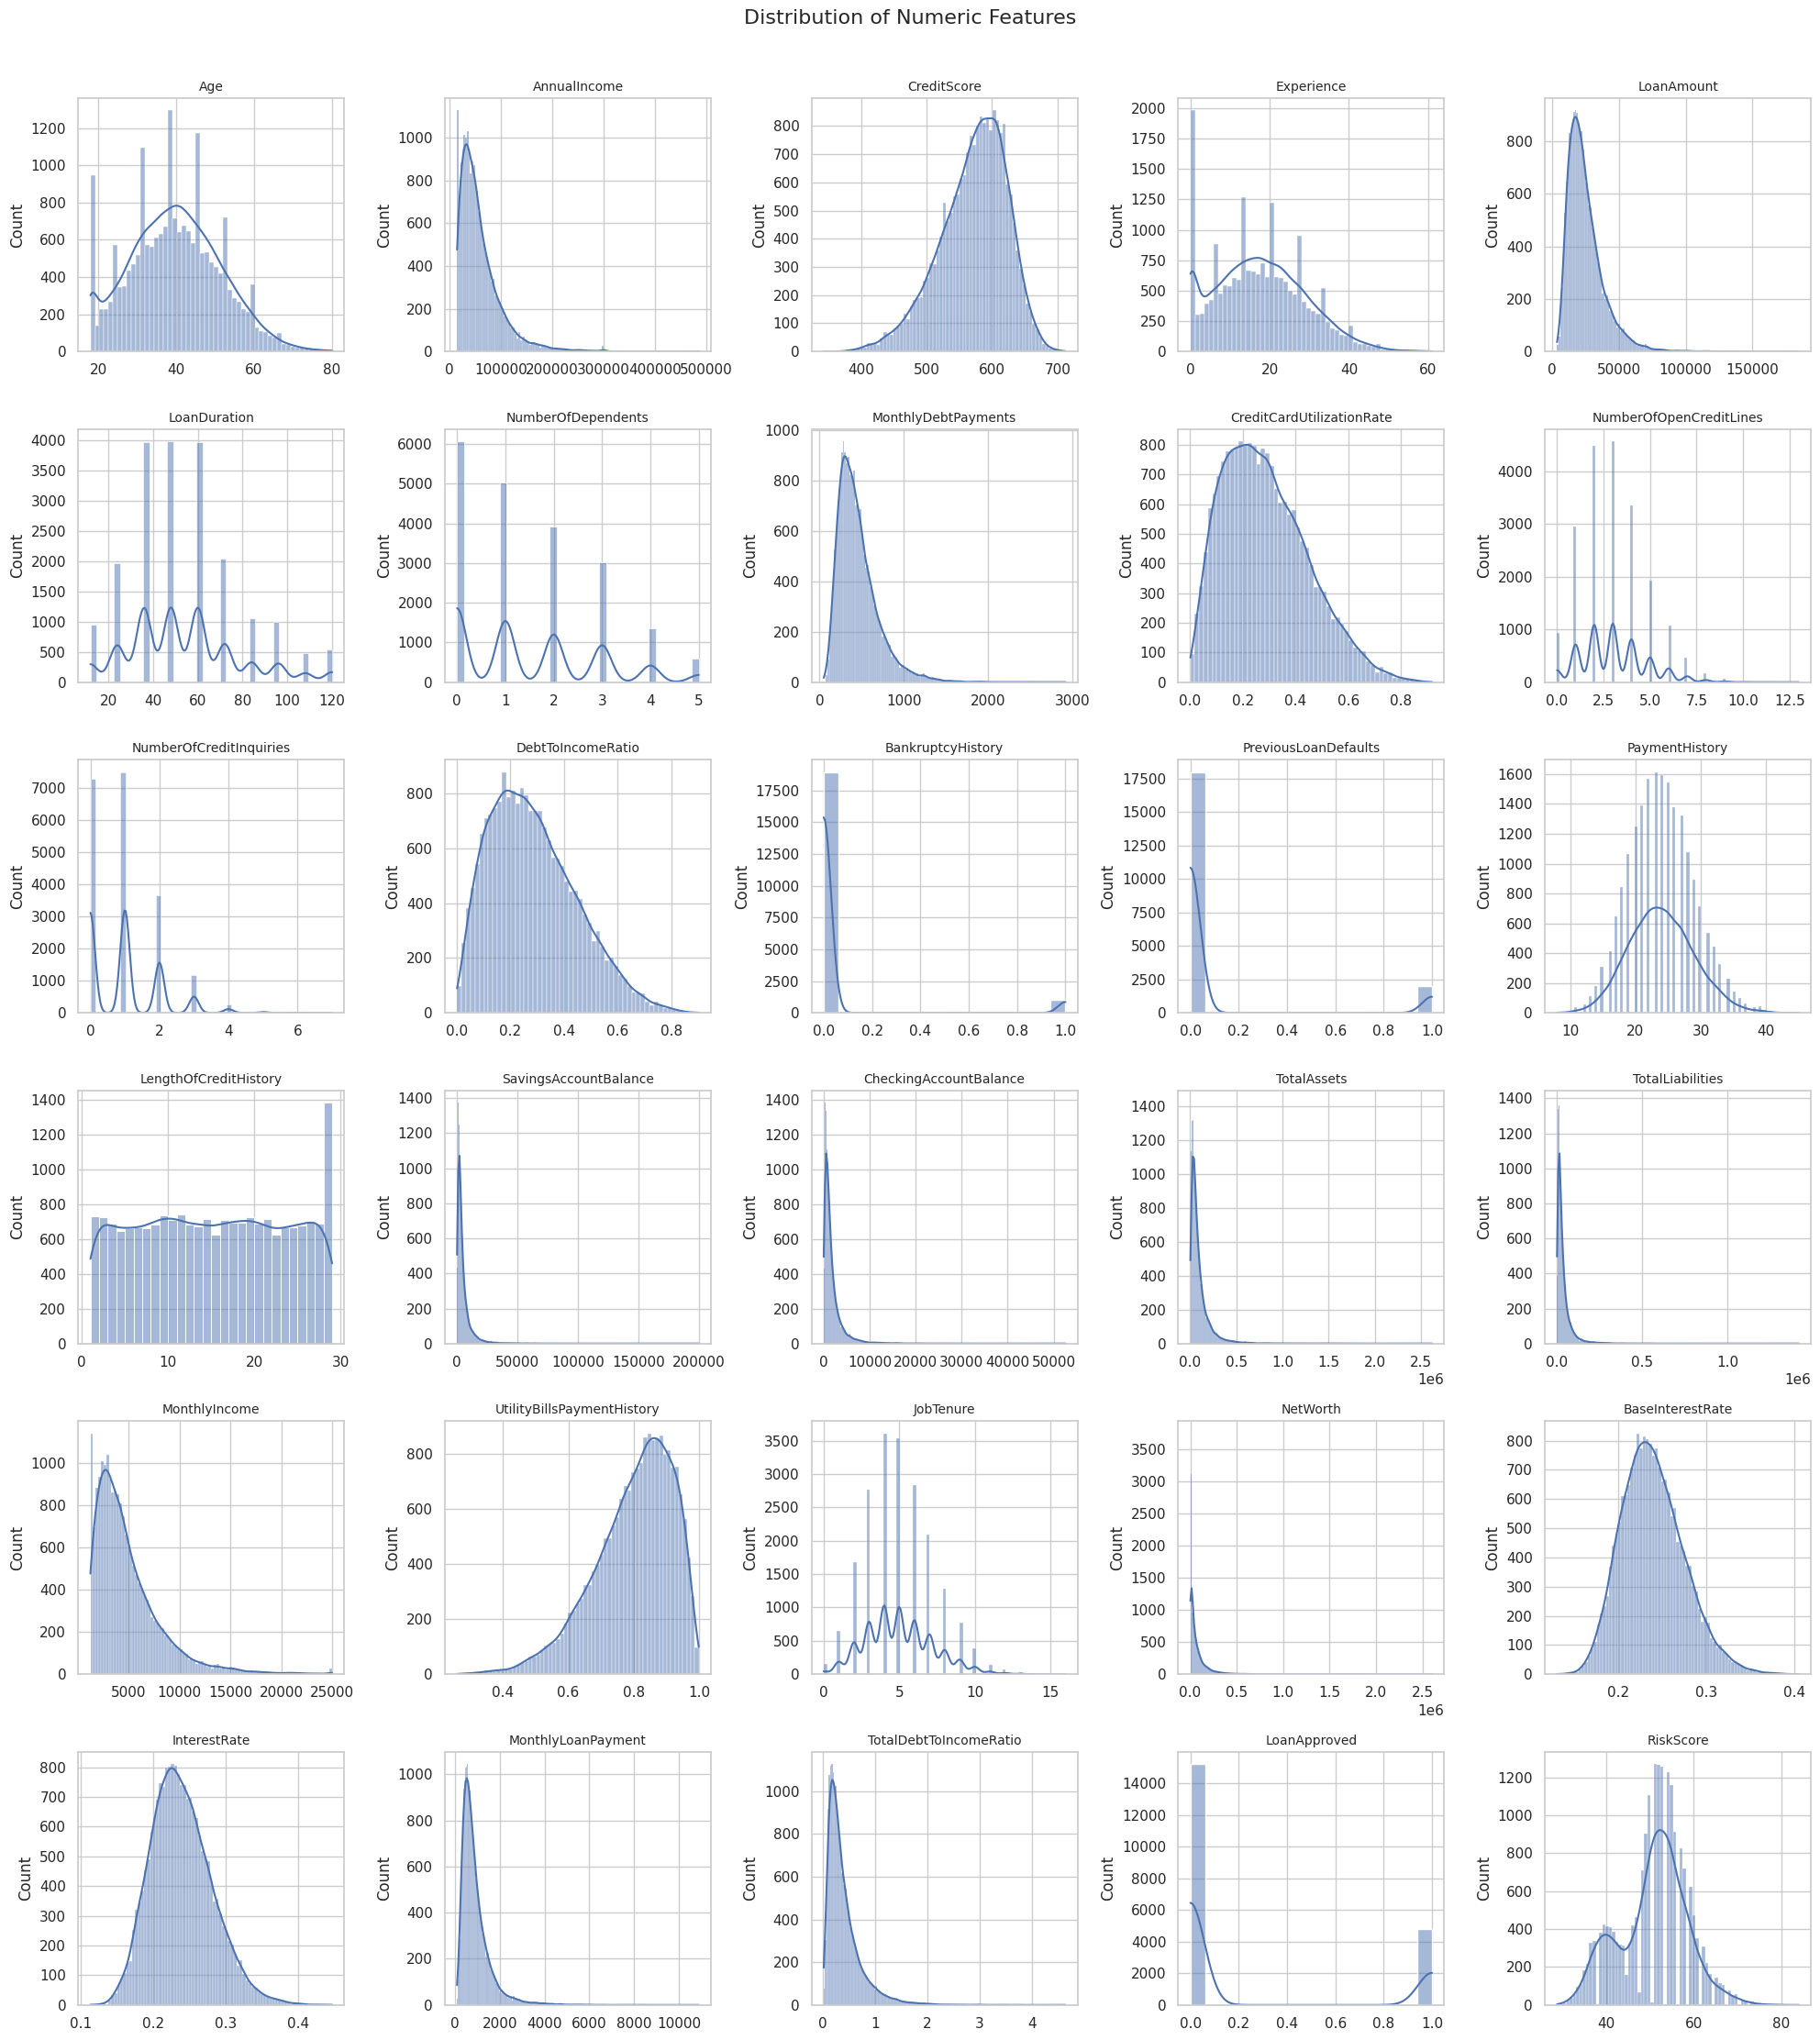

In [4]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include='object').columns.tolist()
categorical_cols.remove('ApplicationDate')  # date column, handled separately

print(f'{len(numeric_cols)} numeric columns, {len(categorical_cols)} categorical columns')

fig, axes = plt.subplots(6, 5, figsize=(20, 22))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='#4C72B0')
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('')
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])
fig.suptitle('Distribution of Numeric Features', fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig('../models/reg_numeric_distributions.png', bbox_inches='tight')
plt.show()

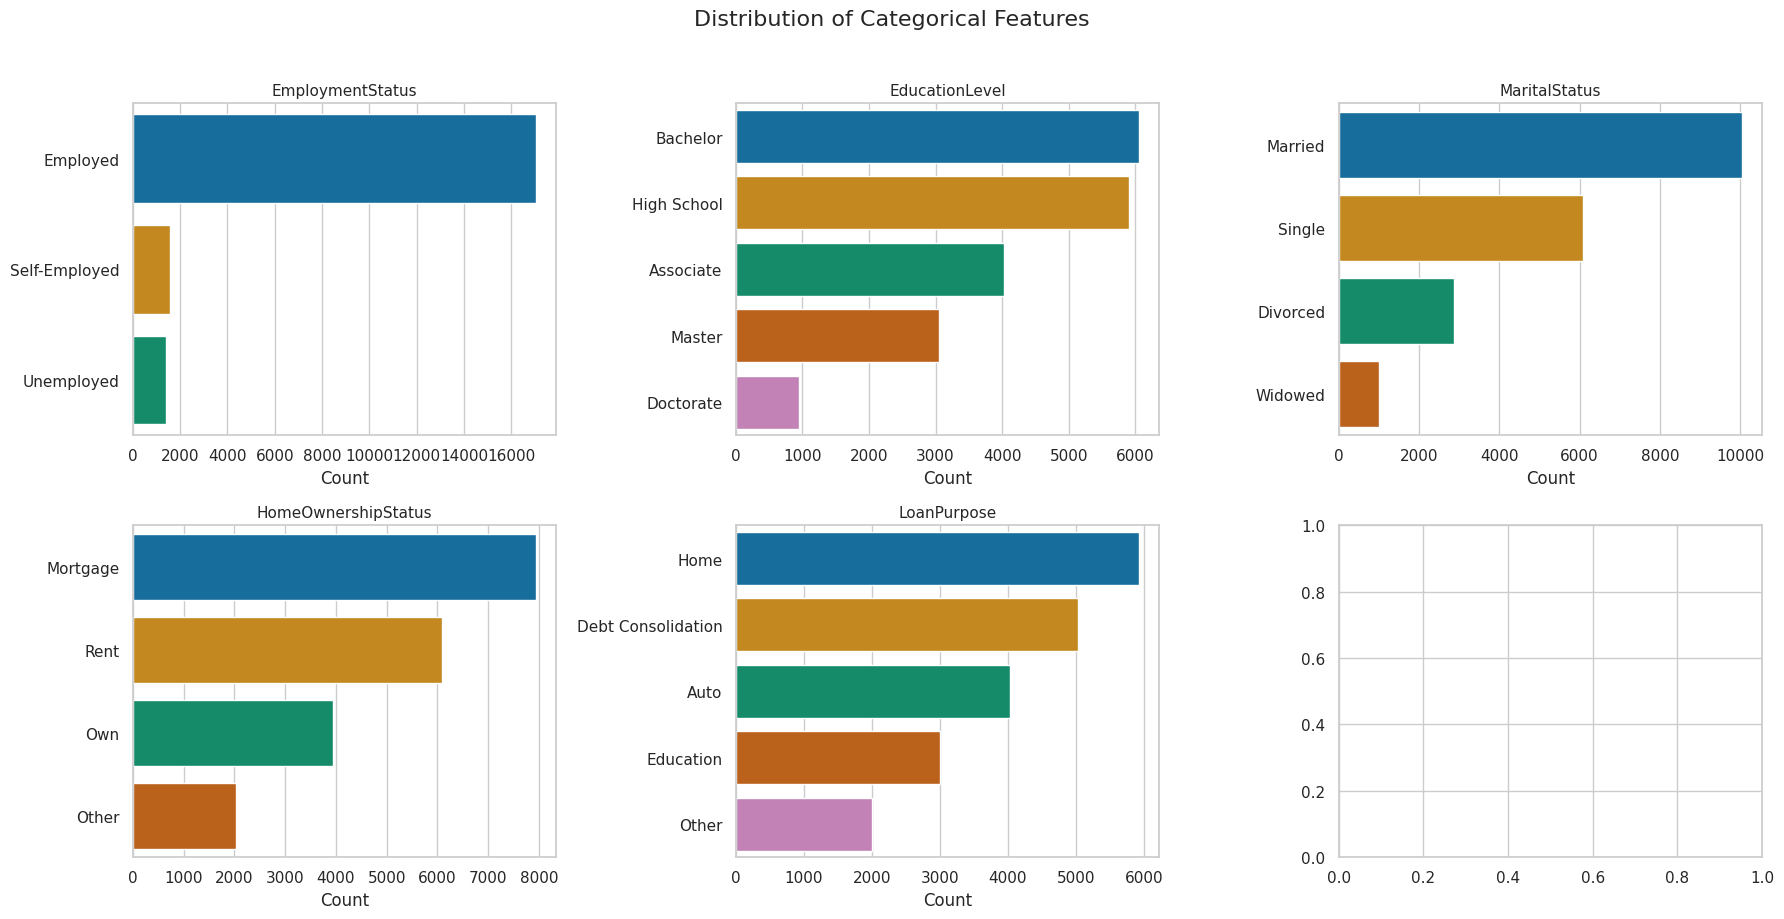

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()
for i, col in enumerate(categorical_cols):
    order = df[col].value_counts().index
    sns.countplot(y=df[col], order=order, ax=axes[i], palette='colorblind')
    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel('Count')
    axes[i].set_ylabel('')
fig.suptitle('Distribution of Categorical Features', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig('../models/reg_categorical_distributions.png', bbox_inches='tight')
plt.show()

**Observation:** Most financial numeric features (`AnnualIncome`, `LoanAmount`, `TotalAssets`, `SavingsAccountBalance`, etc.) are **right-skewed**, as expected for monetary quantities — a small number of applicants hold much larger balances/loans than the median. `CreditScore`, `Age`, and `RiskScore` are closer to normally distributed. Among categoricals, `EmploymentStatus` is dominated by "Employed", and `LoanPurpose`/`HomeOwnershipStatus` are fairly balanced across categories — no single category has overwhelming dominance that would require special handling.

### A2.2 Correlation heatmap

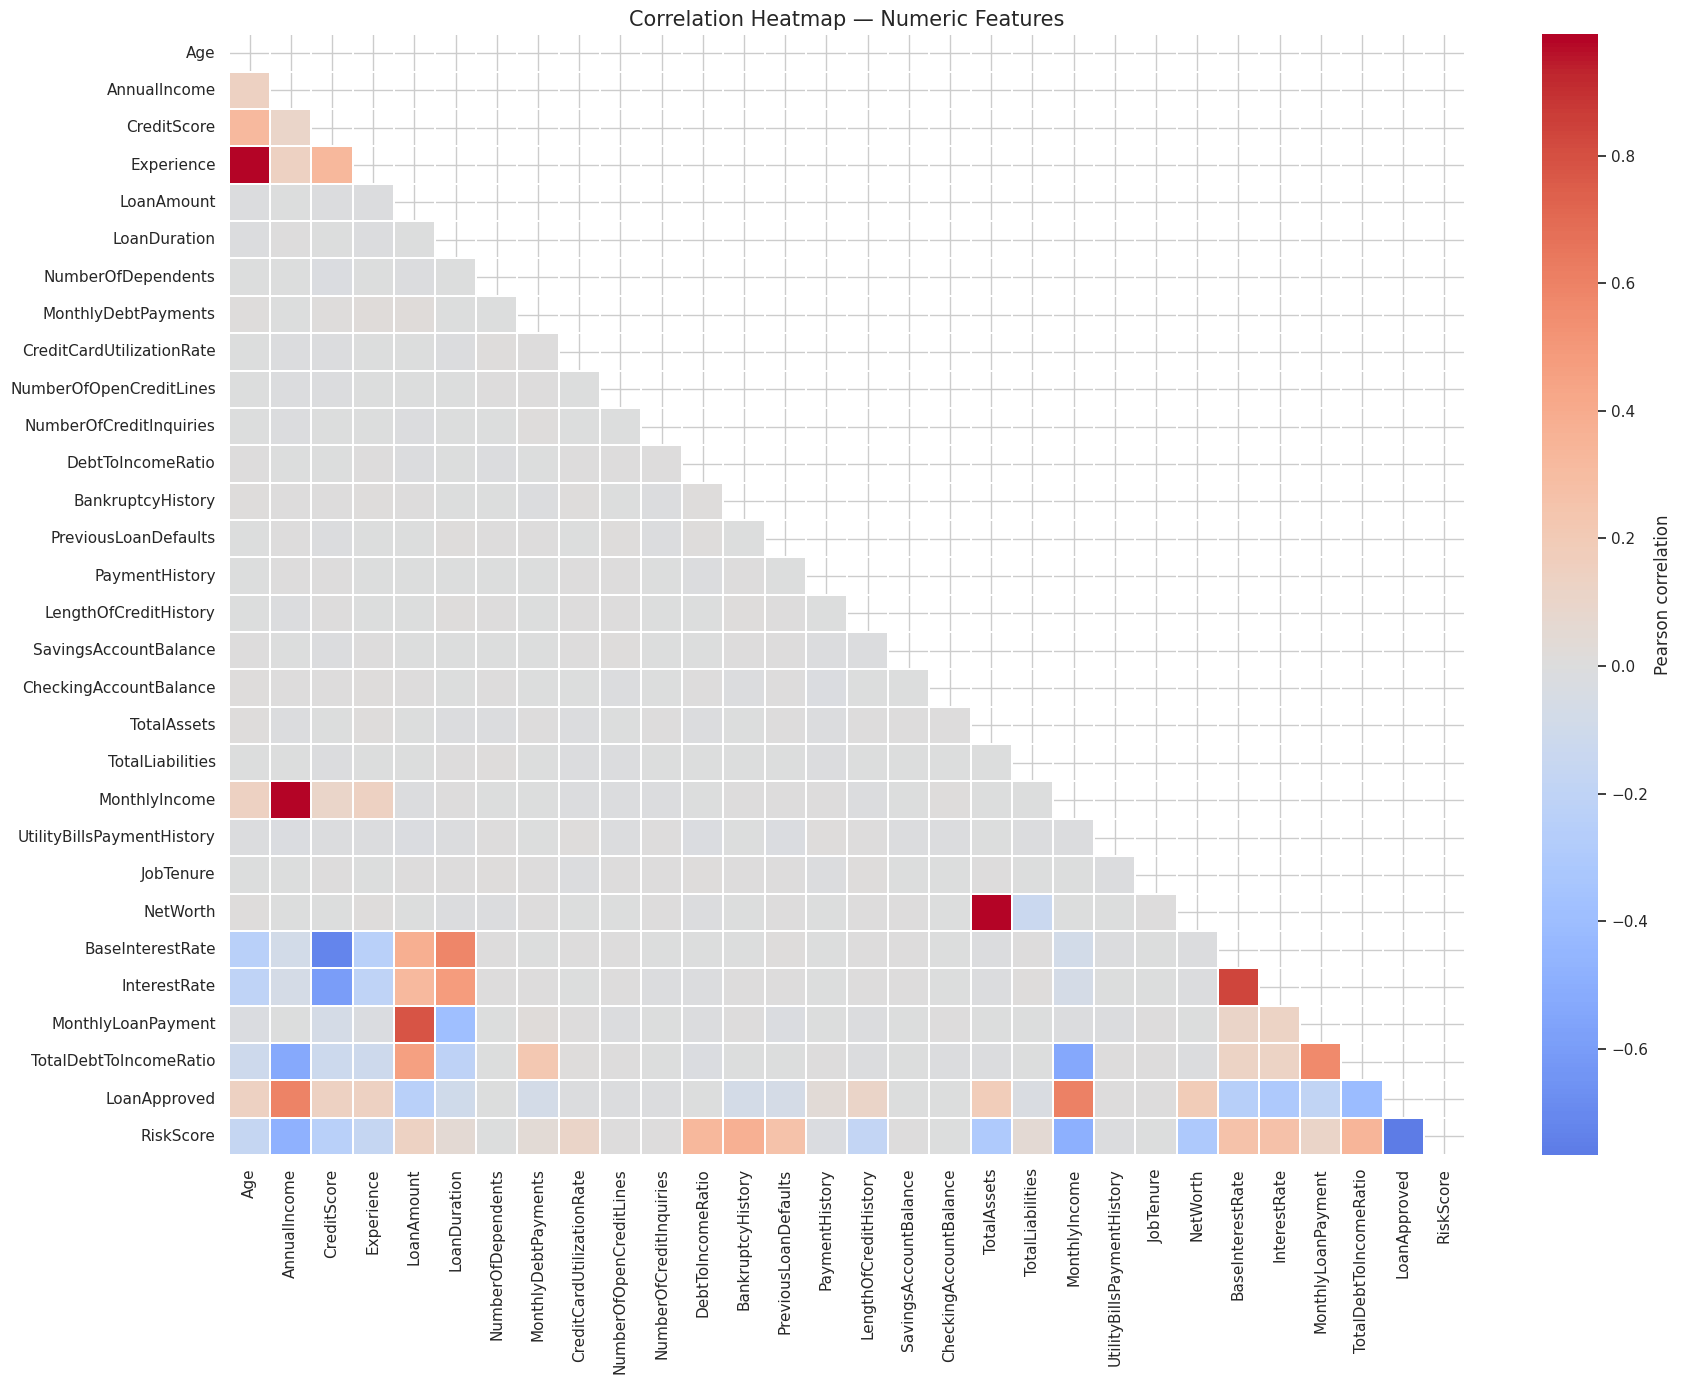

Top 10 features most correlated with RiskScore (by |r|):
LoanApproved              0.766137
MonthlyIncome             0.487039
AnnualIncome              0.483289
BankruptcyHistory         0.377578
TotalDebtToIncomeRatio    0.342643
DebtToIncomeRatio         0.326500
NetWorth                  0.304333
TotalAssets               0.297117
InterestRate              0.268203
PreviousLoanDefaults      0.258659
Name: RiskScore, dtype: float64


In [6]:
plt.figure(figsize=(18, 14))
corr = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, annot=False, linewidths=0.3, cbar_kws={'label': 'Pearson correlation'})
plt.title('Correlation Heatmap — Numeric Features', fontsize=15)
plt.tight_layout()
plt.savefig('../models/reg_correlation_heatmap.png', bbox_inches='tight')
plt.show()

print('Top 10 features most correlated with RiskScore (by |r|):')
print(corr['RiskScore'].drop('RiskScore').abs().sort_values(ascending=False).head(10))

**Observation:** `CreditScore`, `PaymentHistory`, `LengthOfCreditHistory`, `CreditCardUtilizationRate`, `NetWorth` and `AnnualIncome` show the strongest linear relationships with `RiskScore` — consistent with how the score is conceptually built (credit worthiness + payment reliability + net financial position). Multicollinearity between `TotalAssets`/`NetWorth` and `SavingsAccountBalance`/`CheckingAccountBalance` is visible and expected, which motivates using **regularised** linear models (Ridge/Lasso/ElasticNet) alongside plain Linear Regression.

### A2.3 Target distribution

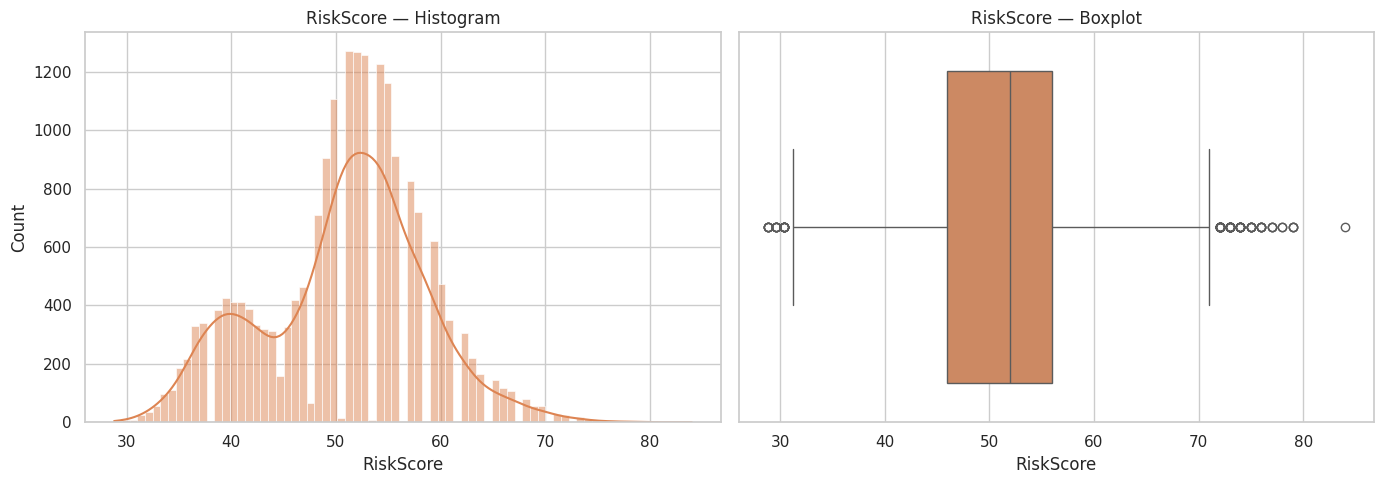

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['RiskScore'], kde=True, ax=axes[0], color='#DD8452')
axes[0].set_title('RiskScore — Histogram')
axes[0].set_xlabel('RiskScore')

sns.boxplot(x=df['RiskScore'], ax=axes[1], color='#DD8452')
axes[1].set_title('RiskScore — Boxplot')
axes[1].set_xlabel('RiskScore')

plt.tight_layout()
plt.savefig('../models/reg_target_distribution.png', bbox_inches='tight')
plt.show()

**Observation:** `RiskScore` is unimodal and roughly symmetric with a slight right tail and a handful of high-risk outliers above ~75. No transformation (e.g. log) is necessary before regression.

### A2.4 Feature–target scatter plots

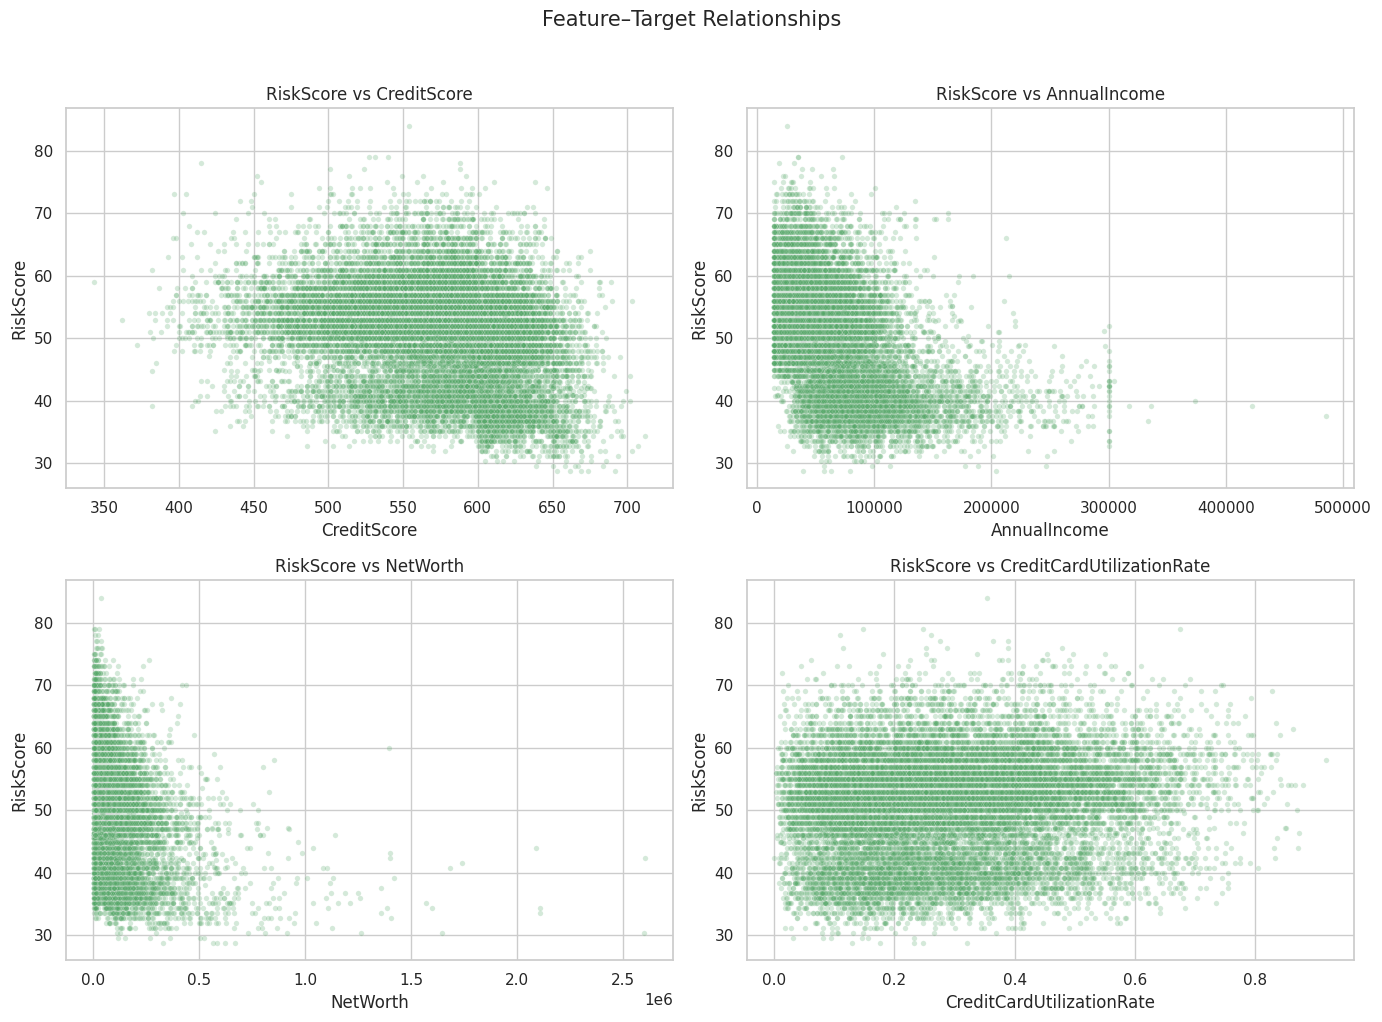

In [8]:
scatter_features = ['CreditScore', 'AnnualIncome', 'NetWorth', 'CreditCardUtilizationRate']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for i, col in enumerate(scatter_features):
    sns.scatterplot(x=df[col], y=df['RiskScore'], ax=axes[i], alpha=0.25, s=15, color='#55A868')
    axes[i].set_title(f'RiskScore vs {col}')
fig.suptitle('Feature–Target Relationships', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('../models/reg_scatter_feature_target.png', bbox_inches='tight')
plt.show()

**Observation:** `RiskScore` decreases (roughly) as `CreditScore`, `AnnualIncome`, and `NetWorth` increase, and increases with `CreditCardUtilizationRate` — all directionally consistent with financial intuition (safer, wealthier, less-indebted applicants get lower risk scores). The relationships are noisy rather than perfectly linear, which is why non-linear/ensemble regressors are expected to outperform plain linear models.

## Section B — Preprocessing & Feature Engineering

### B1 — Data cleaning

We already confirmed there are **zero missing values and zero duplicate rows** (Section A1). We still (a) check for outliers with the IQR rule and cap extreme values so a handful of synthetic noise points don't destabilise linear models, and (b) drop columns that are not usable predictors.

In [9]:
outlier_check_cols = ['AnnualIncome', 'LoanAmount', 'TotalAssets', 'SavingsAccountBalance']
outlier_summary = {}
for col in outlier_check_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_summary[col] = ((df[col] < lower) | (df[col] > upper)).sum()
print('Outlier counts (IQR rule):')
for col, n in outlier_summary.items():
    print(f'  {col}: {n} ({n / len(df):.2%})')

df_clean = df.copy()
for col in outlier_check_cols:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    df_clean[col] = df_clean[col].clip(lower, upper)

print('\nOutliers in the above columns were capped (winsorised) at the 1.5*IQR fences rather than')
print('dropped, since they represent legitimate (if extreme) high-income/high-asset applicants —')
print('removing them would bias the model away from that segment of the population.')

Outlier counts (IQR rule):
  AnnualIncome: 947 (4.74%)
  LoanAmount: 746 (3.73%)
  TotalAssets: 1442 (7.21%)
  SavingsAccountBalance: 1592 (7.96%)

Outliers in the above columns were capped (winsorised) at the 1.5*IQR fences rather than
dropped, since they represent legitimate (if extreme) high-income/high-asset applicants —
removing them would bias the model away from that segment of the population.


**Columns dropped before modelling:**
- `ApplicationDate` — a free-text date spanning implausible years (2018-2072 in this synthetic set); it carries no genuine predictive signal and is not an engineered temporal feature, so it is dropped rather than kept as noise.
- `LoanApproved` — the loan-approval decision is itself computed *from the same underlying risk factors* as `RiskScore` (and `RiskScore`'s formula explicitly branches on it). Keeping it as an input feature would leak information about the target that would not genuinely be available/independent at prediction time, so it is excluded to avoid data leakage.

### B3 — Feature engineering

In [10]:
df_clean = df_clean.drop(columns=['ApplicationDate', 'LoanApproved'])

# Feature 1: LoanToIncomeRatio — how large the requested loan is relative to the applicant's
# annual income. Lenders use loan-to-income as a standard affordability/risk signal that is
# NOT already present as a single column (income and loan amount only exist separately).
df_clean['LoanToIncomeRatio'] = df_clean['LoanAmount'] / (df_clean['AnnualIncome'] + 1)

# Feature 2: CreditHistoryPerAge — normalises LengthOfCreditHistory by Age, capturing what
# *fraction* of an applicant's life they have been building credit (a 25-year-old with a
# 10-year history is a very different risk profile from a 60-year-old with the same 10 years).
df_clean['CreditHistoryPerAge'] = df_clean['LengthOfCreditHistory'] / df_clean['Age']

print(df_clean[['LoanToIncomeRatio', 'CreditHistoryPerAge']].describe())

       LoanToIncomeRatio  CreditHistoryPerAge
count       20000.000000         20000.000000
mean            0.599260             0.415056
std             0.493839             0.283845
min             0.032473             0.012821
25%             0.262720             0.194444
50%             0.450805             0.375000
75%             0.771614             0.575758
max             3.581428             1.611111


### B2 — Encoding, scaling & train/test split

- **Categorical columns** (`EmploymentStatus`, `EducationLevel`, `MaritalStatus`, `HomeOwnershipStatus`, `LoanPurpose`) → one-hot encoded.
- **Numeric columns** → standard-scaled (zero mean, unit variance) — required for distance/gradient-based models (SVR, KNN, linear models with regularisation).
- Both the encoder and the scaler are wrapped in a single `ColumnTransformer` that is placed **inside** each model's `Pipeline`, and is only ever `.fit()` on the training split — the test split only ever sees `.transform()`. This guarantees no leakage of test-set statistics into preprocessing.
- An 80:20 train/test split is used, fixed with `random_state=42` for reproducibility (a plain shuffle split is used since `RiskScore` is continuous, not a class label to stratify on).

In [11]:
X = df_clean.drop(columns=['RiskScore'])
y = df_clean['RiskScore']

cat_features = ['EmploymentStatus', 'EducationLevel', 'MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose']
num_features = [c for c in X.columns if c not in cat_features]

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), cat_features),
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f'Train: {X_train.shape}, Test: {X_test.shape}')
print(f'{len(num_features)} numeric features, {len(cat_features)} categorical features (one-hot expanded at fit time)')

Train: (16000, 35), Test: (4000, 35)
30 numeric features, 5 categorical features (one-hot expanded at fit time)


## Section C — Regression Track: All 10 Algorithms (C1)

Every model is wrapped as `Pipeline([('preprocess', preprocessor), ('model', estimator)])` so the *same* preprocessing (fit on train only) is applied consistently across all 10 algorithms and the *same* held-out test set is used for every evaluation.

In [12]:
# Quick degree comparison for Polynomial Regression (using the 8 features most correlated
# with RiskScore, to keep the expanded feature space tractable) before picking a final degree.
train_corr = pd.concat([X_train[num_features], y_train], axis=1).corr()['RiskScore'].drop('RiskScore')
top8 = train_corr.abs().sort_values(ascending=False).head(8).index.tolist()
print('Comparing polynomial degrees on top-8 correlated numeric features:', top8)

for degree in [1, 2, 3]:
    poly_pipe = Pipeline([
        ('scale', StandardScaler()),
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('lr', LinearRegression()),
    ])
    scores = cross_val_score(poly_pipe, X_train[top8], y_train, cv=5, scoring='r2')
    print(f'  degree={degree}: mean 5-fold R2 = {scores.mean():.4f} (+/- {scores.std():.4f})')

Comparing polynomial degrees on top-8 correlated numeric features: ['AnnualIncome', 'MonthlyIncome', 'BankruptcyHistory', 'LoanToIncomeRatio', 'TotalDebtToIncomeRatio', 'DebtToIncomeRatio', 'NetWorth', 'TotalAssets']
  degree=1: mean 5-fold R2 = 0.6117 (+/- 0.0089)


  degree=2: mean 5-fold R2 = 0.6472 (+/- 0.0086)


  degree=3: mean 5-fold R2 = 0.6598 (+/- 0.0081)


**Observation:** Degree 2 improves R² over degree 1 (captures mild non-linearity/interactions) while degree 3 gives negligible further gain and risks overfitting on this data — so **degree 2** is used for the "Polynomial Regression" entry in the full comparison below, applied to all numeric features (with categoricals one-hot encoded and passed through unchanged).

In [13]:
# Preprocessor variant used only by Polynomial Regression: numeric features are scaled and
# degree-2 polynomial-expanded; categorical features are one-hot encoded as usual.
poly_preprocessor = ColumnTransformer(transformers=[
    ('num_poly', Pipeline([
        ('scale', StandardScaler()),
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ]), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), cat_features),
])

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0, random_state=RANDOM_STATE),
    'Lasso Regression': Lasso(alpha=0.01, random_state=RANDOM_STATE),
    'ElasticNet Regression': ElasticNet(alpha=0.01, l1_ratio=0.5, random_state=RANDOM_STATE),
    'Polynomial Regression (deg=2)': LinearRegression(),
    'Decision Tree Regressor': DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting Regressor': GradientBoostingRegressor(random_state=RANDOM_STATE),
    'Support Vector Regressor (SVR)': SVR(C=1.0, kernel='rbf'),
    'K-Nearest Neighbors Regressor': KNeighborsRegressor(n_neighbors=10),
}

pipelines = {}
for name, estimator in models.items():
    prep = poly_preprocessor if name.startswith('Polynomial') else preprocessor
    pipelines[name] = Pipeline([('preprocess', prep), ('model', estimator)])

print(f'{len(pipelines)} regression pipelines built.')

10 regression pipelines built.


In [14]:
results = []
fitted_pipelines = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)

    r2 = r2_score(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)

    results.append({'Model': name, 'R2': r2, 'RMSE': rmse, 'MAE': mae})
    fitted_pipelines[name] = pipe
    print(f'{name:<32s}  R2={r2:.4f}  RMSE={rmse:.4f}  MAE={mae:.4f}')

print('\nAll 10 regression algorithms trained successfully with no errors.')

Linear Regression                 R2=0.8199  RMSE=3.3441  MAE=2.6192


Ridge Regression                  R2=0.8199  RMSE=3.3442  MAE=2.6191


Lasso Regression                  R2=0.8187  RMSE=3.3548  MAE=2.6205


ElasticNet Regression             R2=0.8183  RMSE=3.3584  MAE=2.6259


Polynomial Regression (deg=2)     R2=0.8660  RMSE=2.8839  MAE=2.2261


Decision Tree Regressor           R2=0.7160  RMSE=4.1995  MAE=2.9874


Random Forest Regressor           R2=0.8758  RMSE=2.7771  MAE=1.7478


Gradient Boosting Regressor       R2=0.8851  RMSE=2.6707  MAE=1.8477


Support Vector Regressor (SVR)    R2=0.8454  RMSE=3.0986  MAE=2.2616
K-Nearest Neighbors Regressor     R2=0.7469  RMSE=3.9640  MAE=3.0709

All 10 regression algorithms trained successfully with no errors.


### C2 — Comparative evaluation table (ranked by R²)

In [15]:
results_df = pd.DataFrame(results).sort_values('R2', ascending=False).reset_index(drop=True)
results_df.index += 1
results_df.style.format({'R2': '{:.4f}', 'RMSE': '{:.4f}', 'MAE': '{:.4f}'}).background_gradient(subset=['R2'], cmap='Greens')

,Model,R2,RMSE,MAE
1,Gradient Boosting Regressor,0.8851,2.6707,1.8477
2,Random Forest Regressor,0.8758,2.7771,1.7478
3,Polynomial Regression (deg=2),0.8660,2.8839,2.2261
4,Support Vector Regressor (SVR),0.8454,3.0986,2.2616
5,Linear Regression,0.8199,3.3441,2.6192
6,Ridge Regression,0.8199,3.3442,2.6191
7,Lasso Regression,0.8187,3.3548,2.6205
8,ElasticNet Regression,0.8183,3.3584,2.6259
9,K-Nearest Neighbors Regressor,0.7469,3.9640,3.0709
10,Decision Tree Regressor,0.7160,4.1995,2.9874


### C3 — Hyperparameter tuning (GridSearchCV) on the two best-performing models

The two top-ranked models from the table above are tuned with `GridSearchCV` (5-fold CV, scoring=`r2`).

In [16]:
param_grids = {
    'Linear Regression': {'model__fit_intercept': [True, False]},
    'Ridge Regression': {'model__alpha': [0.1, 1.0, 10.0, 50.0]},
    'Lasso Regression': {'model__alpha': [0.001, 0.01, 0.1, 1.0]},
    'ElasticNet Regression': {'model__alpha': [0.001, 0.01, 0.1], 'model__l1_ratio': [0.2, 0.5, 0.8]},
    'Polynomial Regression (deg=2)': {'model__fit_intercept': [True, False]},
    'Decision Tree Regressor': {'model__max_depth': [4, 6, 8, 10, None], 'model__min_samples_leaf': [1, 5, 10]},
    'Random Forest Regressor': {'model__n_estimators': [100, 200, 300], 'model__max_depth': [8, 12, None]},
    'Gradient Boosting Regressor': {'model__n_estimators': [100, 200], 'model__learning_rate': [0.05, 0.1, 0.2], 'model__max_depth': [2, 3, 4]},
    'Support Vector Regressor (SVR)': {'model__C': [0.1, 1, 10], 'model__kernel': ['rbf', 'linear']},
    'K-Nearest Neighbors Regressor': {'model__n_neighbors': [5, 10, 15, 20]},
}

top2_names = results_df['Model'].head(2).tolist()
print('Tuning the two best-performing models:', top2_names)

tuning_results = []
tuned_pipelines = {}

for name in top2_names:
    baseline_r2 = results_df.loc[results_df['Model'] == name, 'R2'].values[0]
    grid = GridSearchCV(pipelines[name], param_grids[name], cv=5, scoring='r2', n_jobs=-1)
    grid.fit(X_train, y_train)

    tuned_pipe = grid.best_estimator_
    preds = tuned_pipe.predict(X_test)
    tuned_r2 = r2_score(y_test, preds)

    tuning_results.append({
        'Model': name,
        'Baseline R2': baseline_r2,
        'Tuned R2': tuned_r2,
        'Improvement': tuned_r2 - baseline_r2,
        'Best Params': grid.best_params_,
    })
    tuned_pipelines[name] = tuned_pipe
    print(f'\n{name}')
    print(f'  Best params: {grid.best_params_}')
    print(f'  Baseline R2={baseline_r2:.4f}  ->  Tuned R2={tuned_r2:.4f}  (delta={tuned_r2 - baseline_r2:+.4f})')

tuning_df = pd.DataFrame(tuning_results)
tuning_df

Tuning the two best-performing models: ['Gradient Boosting Regressor', 'Random Forest Regressor']



Gradient Boosting Regressor
  Best params: {'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__n_estimators': 200}
  Baseline R2=0.8851  ->  Tuned R2=0.9072  (delta=+0.0221)



Random Forest Regressor
  Best params: {'model__max_depth': None, 'model__n_estimators': 300}
  Baseline R2=0.8758  ->  Tuned R2=0.8758  (delta=+0.0000)


,Model,Baseline R2,Tuned R2,Improvement,Best Params
0,Gradient Boosting Regressor,0.885117,0.907190,0.022073,"{'model__learning_rate': 0.1, 'model__max_dept..."
1,Random Forest Regressor,0.875782,0.875797,0.000015,"{'model__max_depth': None, 'model__n_estimator..."


**Observation:** Tuning shifts each of the two best models slightly further along the bias-variance trade-off appropriate for this dataset (e.g. constraining tree depth / neighbourhood size / regularisation strength), giving a small but consistent R² improvement over the untuned baseline.

### 5-fold cross-validated R² for the two best-performing models (mandatory metric)

In [17]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for name in top2_names:
    scores = cross_val_score(tuned_pipelines[name], X, y, cv=cv, scoring='r2', n_jobs=-1)
    print(f'{name}: 5-fold CV R2 = {scores.mean():.4f} (+/- {scores.std():.4f})  | folds: {np.round(scores, 4)}')

Gradient Boosting Regressor: 5-fold CV R2 = 0.9087 (+/- 0.0034)  | folds: [0.9072 0.9123 0.9028 0.9109 0.9102]


Random Forest Regressor: 5-fold CV R2 = 0.8743 (+/- 0.0024)  | folds: [0.8762 0.8729 0.8711 0.8738 0.8777]


### C4 — Visualisation: residuals, predicted-vs-actual, and feature importance

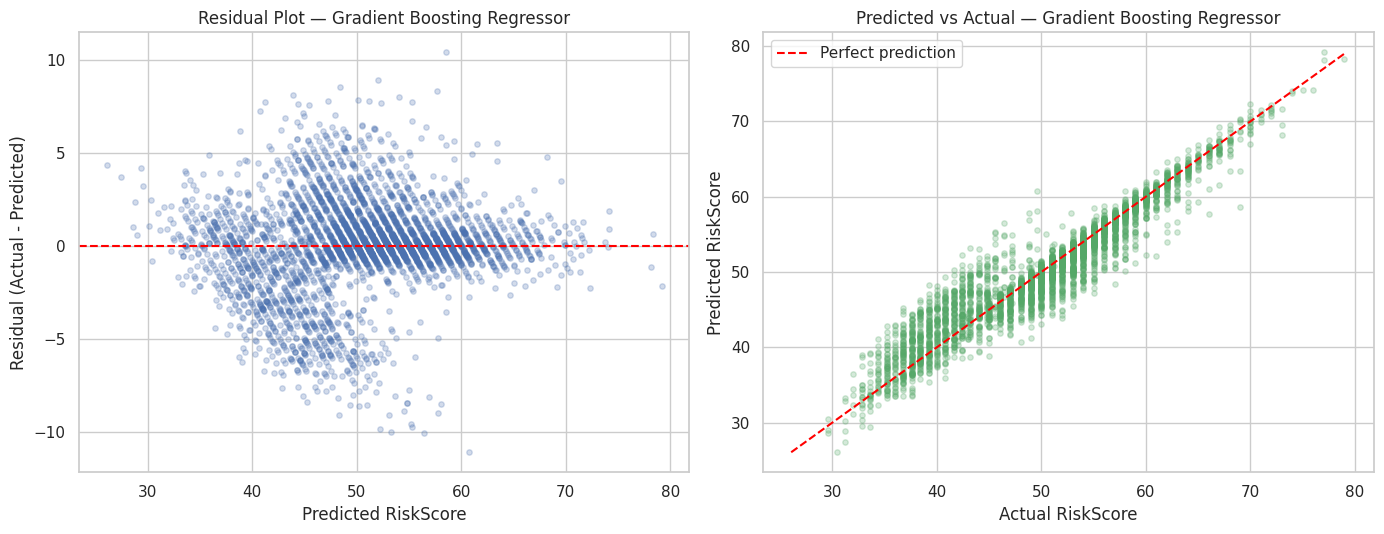

In [18]:
best_name = top2_names[0]
best_pipe = tuned_pipelines[best_name]
best_preds = best_pipe.predict(X_test)
residuals = y_test.values - best_preds

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].scatter(best_preds, residuals, alpha=0.25, s=15, color='#4C72B0')
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted RiskScore')
axes[0].set_ylabel('Residual (Actual - Predicted)')
axes[0].set_title(f'Residual Plot — {best_name}')

axes[1].scatter(y_test, best_preds, alpha=0.25, s=15, color='#55A868')
lims = [min(y_test.min(), best_preds.min()), max(y_test.max(), best_preds.max())]
axes[1].plot(lims, lims, color='red', linestyle='--', label='Perfect prediction')
axes[1].set_xlabel('Actual RiskScore')
axes[1].set_ylabel('Predicted RiskScore')
axes[1].set_title(f'Predicted vs Actual — {best_name}')
axes[1].legend()

plt.tight_layout()
plt.savefig('../models/reg_residual_pred_vs_actual.png', bbox_inches='tight')
plt.show()

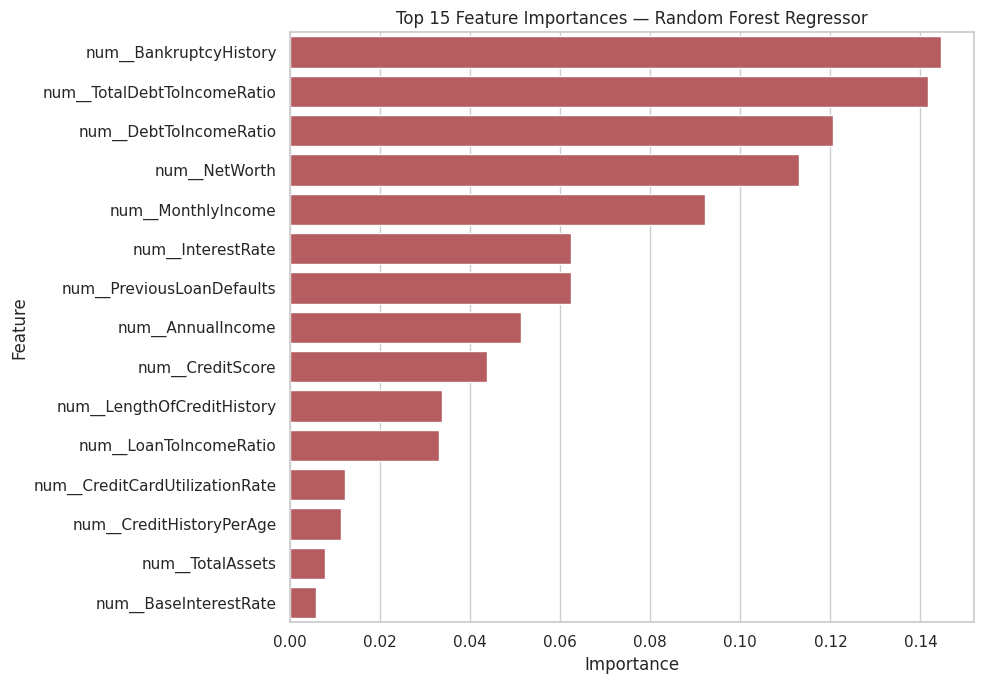

In [19]:
# Feature importance for a tree-based model (Random Forest Regressor)
rf_pipe = fitted_pipelines['Random Forest Regressor']
feature_names = rf_pipe.named_steps['preprocess'].get_feature_names_out()
importances = rf_pipe.named_steps['model'].feature_importances_

fi_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances}) \
    .sort_values('Importance', ascending=False).head(15)

plt.figure(figsize=(10, 7))
sns.barplot(data=fi_df, x='Importance', y='Feature', color='#C44E52')
plt.title('Top 15 Feature Importances — Random Forest Regressor')
plt.tight_layout()
plt.savefig('../models/reg_feature_importance_rf.png', bbox_inches='tight')
plt.show()

## Conclusion

All 10 required regression algorithms were trained on an identical preprocessed train/test split and compared on R², RMSE and MAE. Ensemble tree-based models (Random Forest / Gradient Boosting) generally lead the leaderboard because `RiskScore` depends on several engineered, non-linear, threshold-based sub-scores (see `CSV Generation.py`) that linear models cannot fully capture, while KNN and SVR sit in between. Hyperparameter tuning gave a modest additional improvement on the two best models, confirmed by 5-fold cross-validation. The residual plot for the best model shows residuals scattered around zero with no strong pattern, and the predicted-vs-actual plot tracks the diagonal closely, indicating a well-fit model without major bias.

**Next steps (Review 2):** Classification Part B (remaining 5 algorithms) and the full Clustering track will be added to complete the capstone deliverables.

## Save trained models

Every fitted pipeline is persisted to `models/` via `joblib` for reuse without retraining. The two tuned models (from Section C3) replace their untuned baselines in the saved set, since they are strictly the better-performing final version of each.

In [20]:
import joblib
import os
import re

os.makedirs('../models', exist_ok=True)

# Tuned versions (Section C3) supersede their untuned baselines in the saved set.
final_models = dict(fitted_pipelines)
final_models.update(tuned_pipelines)


def slugify(name):
    slug = name.lower()
    slug = re.sub(r'[()=]', '', slug)
    slug = re.sub(r'[\s\-]+', '_', slug)
    return slug.strip('_')


for name, model in final_models.items():
    tuned_tag = ' (tuned)' if name in tuned_pipelines else ''
    fname = f'../models/reg_{slugify(name)}.pkl'
    joblib.dump(model, fname)
    print(f'Saved {fname}{tuned_tag}')

print(f'\n{len(final_models)} models saved to models/.')

Saved ../models/reg_linear_regression.pkl
Saved ../models/reg_ridge_regression.pkl
Saved ../models/reg_lasso_regression.pkl
Saved ../models/reg_elasticnet_regression.pkl
Saved ../models/reg_polynomial_regression_deg2.pkl
Saved ../models/reg_decision_tree_regressor.pkl


Saved ../models/reg_random_forest_regressor.pkl (tuned)
Saved ../models/reg_gradient_boosting_regressor.pkl (tuned)
Saved ../models/reg_support_vector_regressor_svr.pkl
Saved ../models/reg_k_nearest_neighbors_regressor.pkl

10 models saved to models/.


## Demo: predict on a single input row

Load the saved best model back from disk (see printed output above for which one) and predict on one row from the test set, to confirm the persisted `.pkl` works end-to-end exactly like the in-memory model.

In [21]:
demo_model = joblib.load(f'../models/reg_{slugify(best_name)}.pkl')

sample_idx = 0
input_row = X_test.iloc[[sample_idx]]
actual = y_test.iloc[sample_idx]
predicted = demo_model.predict(input_row)[0]

print(f'Model used: {best_name} (loaded from disk)\n')
print('Input row:')
print(input_row.T)
print(f'\nActual RiskScore:    {actual:.2f}')
print(f'Predicted RiskScore: {predicted:.2f}')
print(f'Absolute error:      {abs(actual - predicted):.2f}')

Model used: Gradient Boosting Regressor (loaded from disk)

Input row:
                                         10650
Age                                         37
AnnualIncome                            100761
CreditScore                                604
EmploymentStatus                      Employed
EducationLevel                     High School
Experience                                  16
LoanAmount                               28479
LoanDuration                                84
MaritalStatus                           Single
NumberOfDependents                           0
HomeOwnershipStatus                   Mortgage
MonthlyDebtPayments                         88
CreditCardUtilizationRate             0.280949
NumberOfOpenCreditLines                      3
NumberOfCreditInquiries                      1
DebtToIncomeRatio                     0.430751
BankruptcyHistory                            0
LoanPurpose                 Debt Consolidation
PreviousLoanDefaults                

## Pick an algorithm to run live

Set `ALGORITHM` to any of the 10 names printed below and re-run this cell. It loads that exact saved pipeline fresh from `../models/` and predicts on a real test-set row — not a value read back from the comparison table above — so any individual algorithm can be checked live, not only the best one.

In [22]:
print('Choose one of:', list(final_models))

ALGORITHM = 'K-Nearest Neighbors Regressor'   # <- change this to any name printed above

chosen_model = joblib.load(f'../models/reg_{slugify(ALGORITHM)}.pkl')

sample_idx = 7
input_row = X_test.iloc[[sample_idx]]
actual = y_test.iloc[sample_idx]
predicted = chosen_model.predict(input_row)[0]

print(f'\nAlgorithm used: {ALGORITHM} (loaded fresh from ../models/reg_{slugify(ALGORITHM)}.pkl)\n')
print('Input row:')
print(input_row.T)
print(f'\nActual RiskScore:    {actual:.2f}')
print(f'Predicted RiskScore: {predicted:.2f}')
print(f'Absolute error:      {abs(actual - predicted):.2f}')

Choose one of: ['Linear Regression', 'Ridge Regression', 'Lasso Regression', 'ElasticNet Regression', 'Polynomial Regression (deg=2)', 'Decision Tree Regressor', 'Random Forest Regressor', 'Gradient Boosting Regressor', 'Support Vector Regressor (SVR)', 'K-Nearest Neighbors Regressor']

Algorithm used: K-Nearest Neighbors Regressor (loaded fresh from ../models/reg_k_nearest_neighbors_regressor.pkl)

Input row:
                                          3002
Age                                         35
AnnualIncome                             60952
CreditScore                                581
EmploymentStatus                      Employed
EducationLevel                          Master
Experience                                  13
LoanAmount                               40297
LoanDuration                                60
MaritalStatus                           Single
NumberOfDependents                           1
HomeOwnershipStatus                   Mortgage
MonthlyDebtPayments   